# ПР-1. Подготовка окружения и первичный анализ данных
**Проект:** CryptoMind AI — интеллектуальный анализ крипторынка
**Выполнил:** <Баргыбаев Нуртилек, CS32>

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__)

Python: 3.12.8
pandas: 3.0.6 | numpy: 2.5.4


## 1. Датасет и его обоснование
Дневные свечи (OHLCV) пар BTC/USDT, ETH/USDT, SOL/USDT с биржи Binance (открытый REST API).
Загрузка и сборка полностью воспроизводимы: `python src/prepare_data.py`.
Период: BTC/ETH — 17.08.2017…13.10.2026, SOL — 11.08.2020…13.10.2026. Всего 8945 строк.

| Колонка | Тип | Описание |
|---|---|---|
| date | дата | день свечи (UTC) |
| open / high / low / close | float | цена открытия / максимум / минимум / закрытия, USDT |
| volume | float | объём торгов в монетах |
| quote_volume | float | объём торгов в USDT |
| trades | int | число сделок за день |
| taker_buy_base_volume | float | объём покупок «в рынок», монеты |
| taker_buy_quote_volume | float | объём покупок «в рынок», USDT |
| symbol | str | торговая пара |
| open_time | int | служебная метка времени (мс, UTC) |

In [2]:
df = pd.read_csv("../data/processed/crypto_daily.csv")
df.head()

,open_time,open,high,low,close,volume,quote_volume,trades,taker_buy_base_volume,taker_buy_quote_volume,symbol,date
0,1502928000000,4261.48,4485.39,4200.74,4285.08,795.150377,3.454770e+06,3427,616.248541,2.678216e+06,BTCUSDT,2017-08-17
1,1503014400000,4285.08,4371.52,3938.77,4108.37,1199.888264,5.086958e+06,5233,972.868710,4.129123e+06,BTCUSDT,2017-08-18
2,1503100800000,4108.37,4184.69,3850.00,4139.98,381.309763,1.549484e+06,2153,274.336042,1.118002e+06,BTCUSDT,2017-08-19
3,1503187200000,4120.98,4211.08,4032.62,4086.29,467.083022,1.930364e+06,2321,376.795947,1.557401e+06,BTCUSDT,2017-08-20
4,1503273600000,4069.13,4119.62,3911.79,4016.00,691.743060,2.797232e+06,3972,557.356107,2.255663e+06,BTCUSDT,2017-08-21


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 8945 entries, 0 to 8944
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_time               8945 non-null   int64  
 1   open                    8945 non-null   float64
 2   high                    8945 non-null   float64
 3   low                     8945 non-null   float64
 4   close                   8945 non-null   float64
 5   volume                  8945 non-null   float64
 6   quote_volume            8945 non-null   float64
 7   trades                  8945 non-null   int64  
 8   taker_buy_base_volume   8945 non-null   float64
 9   taker_buy_quote_volume  8945 non-null   float64
 10  symbol                  8945 non-null   str    
 11  date                    8945 non-null   str    
dtypes: float64(8), int64(2), str(2)
memory usage: 838.7 KB


,count,mean,std,min,25%,50%,75%,max
open_time,8945.0,1.659260e+12,8.013730e+10,1.502928e+12,1.598659e+12,1.663114e+12,1.727482e+12,1.791850e+12
open,8945.0,1.528903e+04,2.714289e+04,1.198700e+00,1.752100e+02,2.281870e+03,1.191099e+04,1.246585e+05
high,8945.0,1.560829e+04,2.762589e+04,1.388800e+00,1.805200e+02,2.337500e+03,1.233803e+04,1.261996e+05
low,8945.0,1.494605e+04,2.662805e+04,1.030100e+00,1.688800e+02,2.195840e+03,1.156250e+04,1.230840e+05
close,8945.0,1.529812e+04,2.715199e+04,1.198000e+00,1.752200e+02,2.283140e+03,1.192197e+04,1.246585e+05
volume,8945.0,1.275181e+06,2.392419e+06,2.281081e+02,4.724599e+04,3.079973e+05,1.383412e+06,3.496502e+07
quote_volume,8945.0,1.071680e+09,1.415966e+09,3.027397e+05,1.782766e+08,5.763211e+08,1.450131e+09,1.746531e+10
trades,8945.0,1.483127e+06,1.879381e+06,1.431000e+03,2.613170e+05,8.164660e+05,1.868671e+06,1.672892e+07
taker_buy_base_volume,8945.0,6.345021e+05,1.197231e+06,5.619014e+01,2.336219e+04,1.545576e+05,6.806007e+05,1.708472e+07
taker_buy_quote_volume,8945.0,5.306289e+08,7.021531e+08,1.561580e+05,8.927990e+07,2.864652e+08,7.191098e+08,8.783916e+09


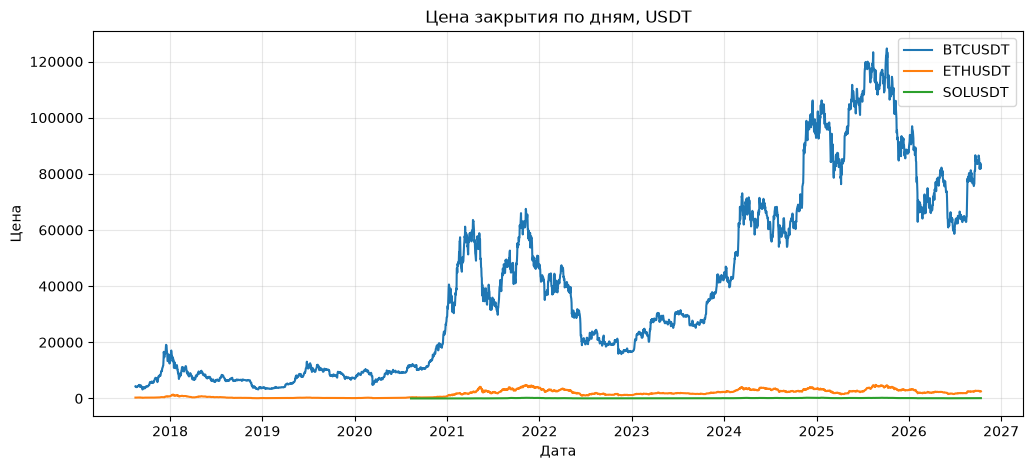

In [4]:
plt.figure(figsize=(12, 5))
for sym in ["BTCUSDT", "ETHUSDT", "SOLUSDT"]:
    d = df[df["symbol"] == sym]
    plt.plot(pd.to_datetime(d["date"]), d["close"], label=sym)
plt.title("Цена закрытия по дням, USDT")
plt.xlabel("Дата")
plt.ylabel("Цена")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 2. Первичные выводы
(2–3 предложения своими словами: сколько данных и за какой период, что видно на графике —
общий восходящий тренд с глубокими просадками, волатильность младших монет выше BTC.)